In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [20]:
df = pd.read_csv("../dataset/retail_sales_dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (1000, 9)


In [21]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB


In [23]:
df.isnull().sum()

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

In [24]:
df.select_dtypes(include=np.number).columns

Index(['Transaction ID', 'Age', 'Quantity', 'Price per Unit', 'Total Amount'], dtype='str')

In [25]:
df.select_dtypes(include=np.number).mean()

Transaction ID    500.500
Age                41.392
Quantity            2.514
Price per Unit    179.890
Total Amount      456.000
dtype: float64

In [26]:
df.select_dtypes(include=np.number).median()

Transaction ID    500.5
Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64

In [27]:
df.select_dtypes(include=np.number).mode().iloc[0]

Transaction ID     1.0
Age               43.0
Quantity           4.0
Price per Unit    50.0
Total Amount      50.0
Name: 0, dtype: float64

In [28]:
df.select_dtypes(include=np.number).std()

Transaction ID    288.819436
Age                13.681430
Quantity            1.132734
Price per Unit    189.681356
Total Amount      559.997632
dtype: float64

In [29]:
numeric_cols = df.select_dtypes(include=np.number).columns

statistics = pd.DataFrame({
    "Mean": df[numeric_cols].mean(),
    "Median": df[numeric_cols].median(),
    "Mode": df[numeric_cols].mode().iloc[0],
    "Standard Deviation": df[numeric_cols].std()
})

statistics

,Mean,Median,Mode,Standard Deviation
Transaction ID,500.500,500.5,1.0,288.819436
Age,41.392,42.0,43.0,13.681430
Quantity,2.514,3.0,4.0,1.132734
Price per Unit,179.890,50.0,50.0,189.681356
Total Amount,456.000,135.0,50.0,559.997632


In [30]:
df["Date"] = pd.to_datetime(df["Date"])

print(df["Date"].dtype)

datetime64[us]


In [31]:
monthly_sales = df.groupby(
    df["Date"].dt.to_period("M")
)["Total Amount"].sum()

monthly_sales

Date
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64

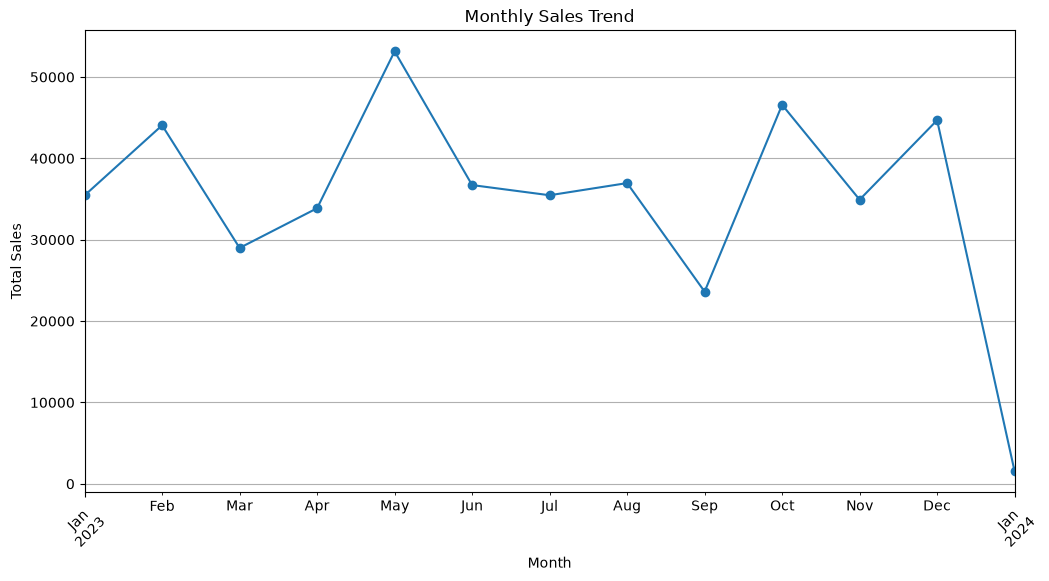

In [32]:
plt.figure(figsize=(12, 6))

monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

### Observation — Monthly Sales Trend

The monthly sales trend shows how total sales changed over time. 
The chart helps identify months with relatively higher or lower sales 
and highlights overall fluctuations in sales performance.

In [33]:
quarterly_sales = df.groupby(
    df["Date"].dt.to_period("Q")
)["Total Amount"].sum()

quarterly_sales

Date
2023Q1    108500
2023Q2    123735
2023Q3     96045
2023Q4    126190
2024Q1      1530
Freq: Q-DEC, Name: Total Amount, dtype: int64

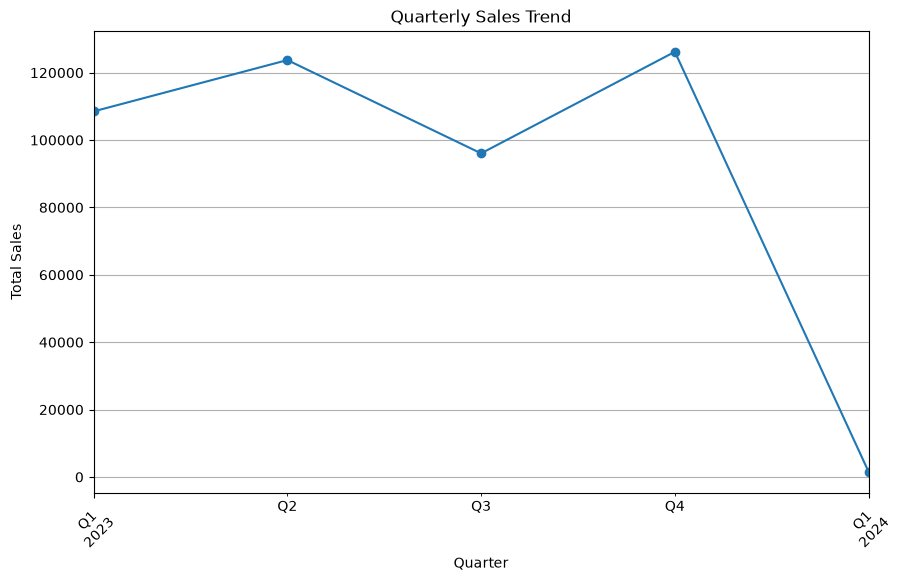

In [34]:
plt.figure(figsize=(10, 6))

quarterly_sales.plot(kind="line", marker="o")

plt.title("Quarterly Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

### Observation — Quarterly Sales Trend

The quarterly sales trend shows how total sales changed across different
quarters. The chart helps identify periods of relatively higher or lower
sales and provides an overview of broader sales patterns over time.

In [35]:
bins = [0, 18, 25, 35, 45, 55, 65, 100]
labels = [
    "Under 18",
    "18-24",
    "25-34",
    "35-44",
    "45-54",
    "55-64",
    "65+"
]

df["Age Group"] = pd.cut(
    df["Age"],
    bins=bins,
    labels=labels,
    right=False
)

df["Age Group"].value_counts().sort_index()

Age Group
Under 18      0
18-24       149
25-34       203
35-44       207
45-54       225
55-64       216
65+           0
Name: count, dtype: int64

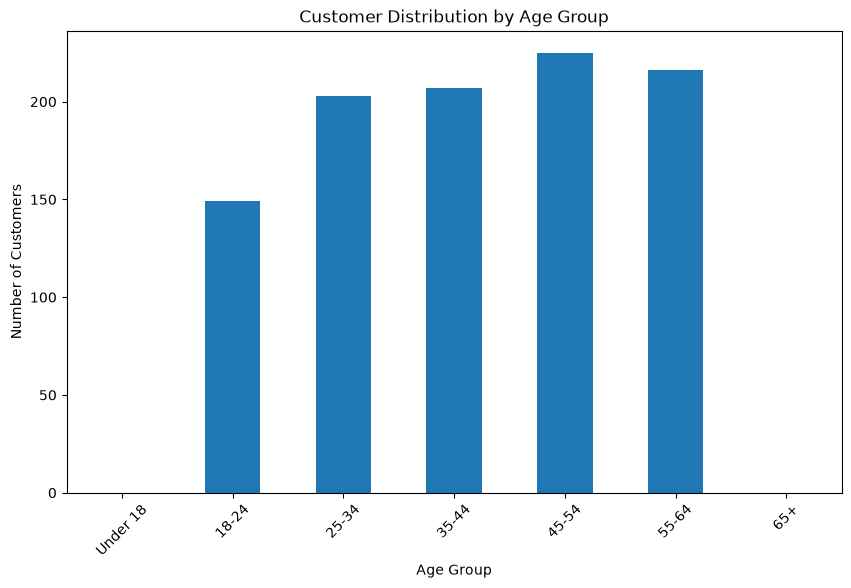

In [36]:
age_group_counts = df["Age Group"].value_counts().sort_index()

plt.figure(figsize=(10, 6))

age_group_counts.plot(kind="bar")

plt.title("Customer Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

plt.show()

### Observation — Customer Age Groups

The age-group analysis shows the distribution of customers across different
age ranges. The chart helps identify which age groups represent a larger
share of the customer base and can support customer-targeting decisions.

In [37]:
gender_counts = df["Gender"].value_counts()

print(gender_counts)

Gender
Female    510
Male      490
Name: count, dtype: int64


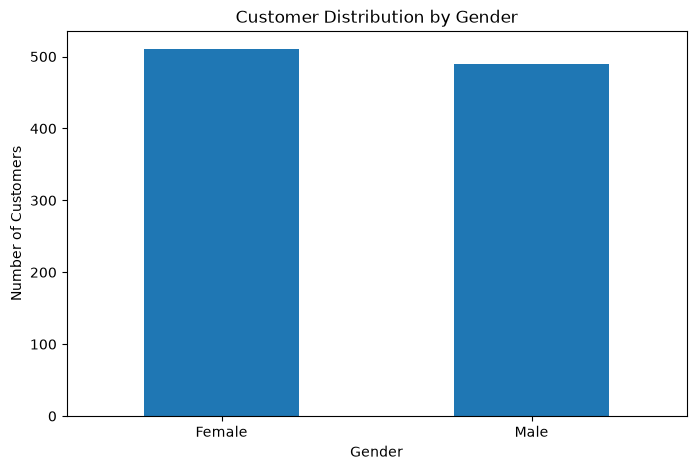

In [38]:
plt.figure(figsize=(8, 5))

gender_counts.plot(kind="bar")

plt.title("Customer Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.show()

### Observation — Customer Gender

The gender analysis shows the distribution of customers across different
gender groups. The chart helps identify the composition of the customer
base and can support demographic-based marketing and customer analysis.

In [39]:
category_sales = df.groupby("Product Category")["Quantity"].sum().sort_values(ascending=False)

print(category_sales)

Product Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64


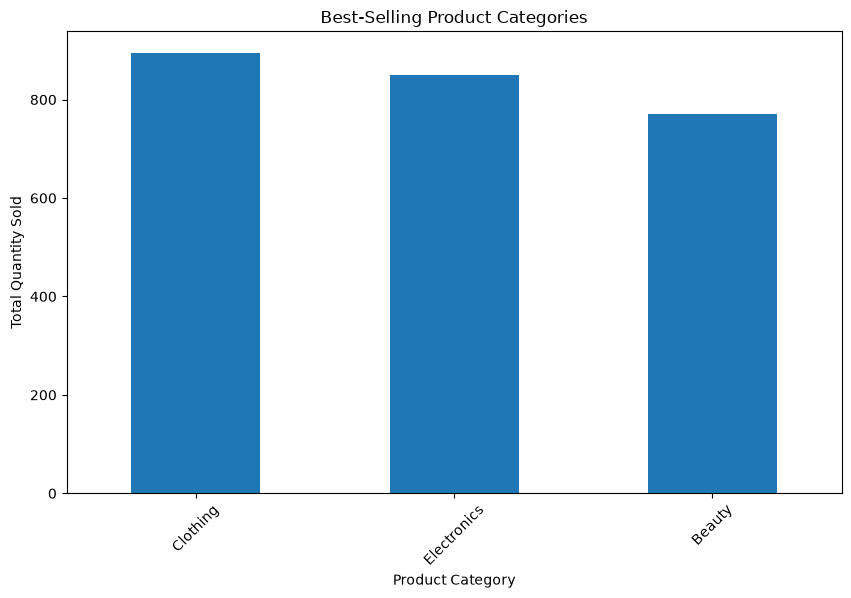

In [40]:
plt.figure(figsize=(10, 6))

category_sales.plot(kind="bar")

plt.title("Best-Selling Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Total Quantity Sold")
plt.xticks(rotation=45)

plt.show()

In [41]:
category_revenue = df.groupby("Product Category")["Total Amount"].sum().sort_values(ascending=False)

print(category_revenue)

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64


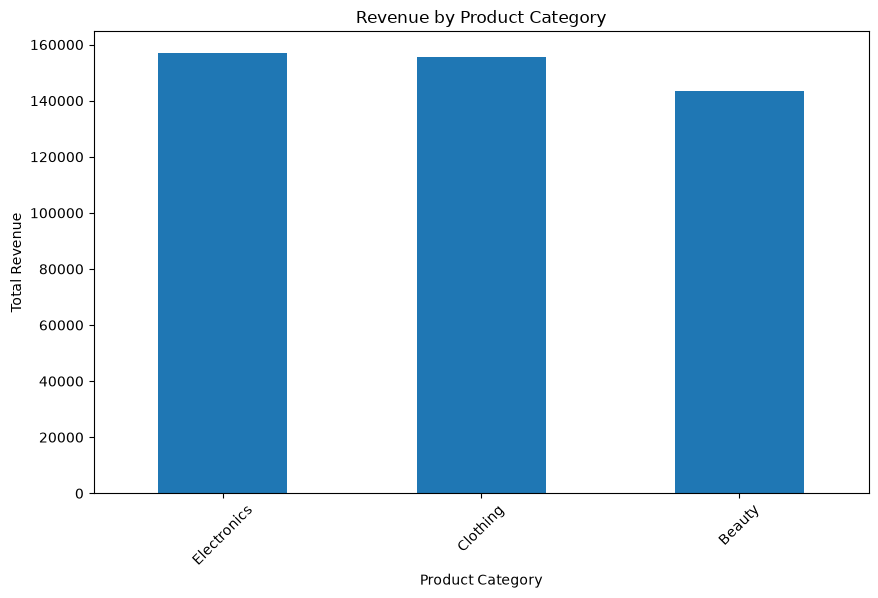

In [42]:
plt.figure(figsize=(10, 6))

category_revenue.plot(kind="bar")

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)

plt.show()

### Observation — Product Category Analysis

The product category analysis shows differences in sales volume and revenue
across categories. Some categories contribute more to the total quantity sold,
while others generate higher revenue. These insights can help businesses
identify strong-performing categories and make better inventory and marketing
decisions.

**Dataset Limitation:** The dataset does not contain a separate Product Name
column. Therefore, the analysis is performed at the Product Category level
instead of identifying the top 10 individual products.

In [44]:
correlation_matrix = df[
    ["Age", "Quantity", "Price per Unit", "Total Amount"]
].corr()

print(correlation_matrix)

                     Age  Quantity  Price per Unit  Total Amount
Age             1.000000 -0.023737       -0.038423     -0.060568
Quantity       -0.023737  1.000000        0.017501      0.373707
Price per Unit -0.038423  0.017501        1.000000      0.851925
Total Amount   -0.060568  0.373707        0.851925      1.000000


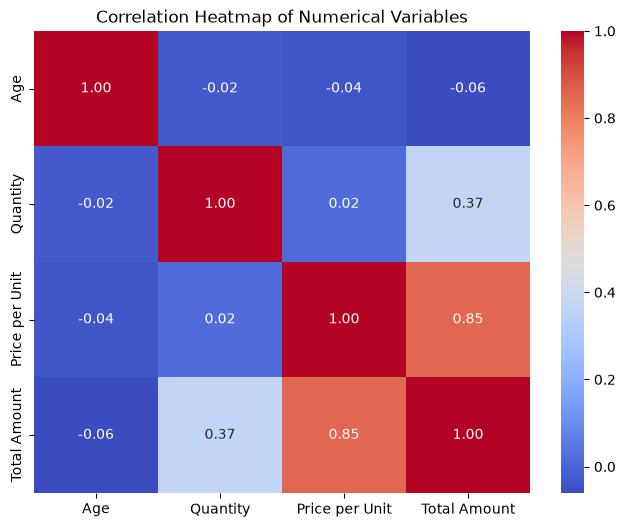

In [45]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Variables")

plt.show()

### Observation — Correlation Analysis

The correlation heatmap shows the relationships between numerical variables
such as age, quantity, price per unit, and total amount. Stronger positive or
negative correlation values indicate stronger relationships between variables.
The analysis can help identify variables that are closely associated with
sales performance.

In [46]:
age_group_spending = df.groupby("Age Group", observed=True)["Total Amount"].mean()

print(age_group_spending)

Age Group
18-24    501.006711
25-34    478.275862
35-44    467.801932
45-54    432.155556
55-64    417.546296
Name: Total Amount, dtype: float64


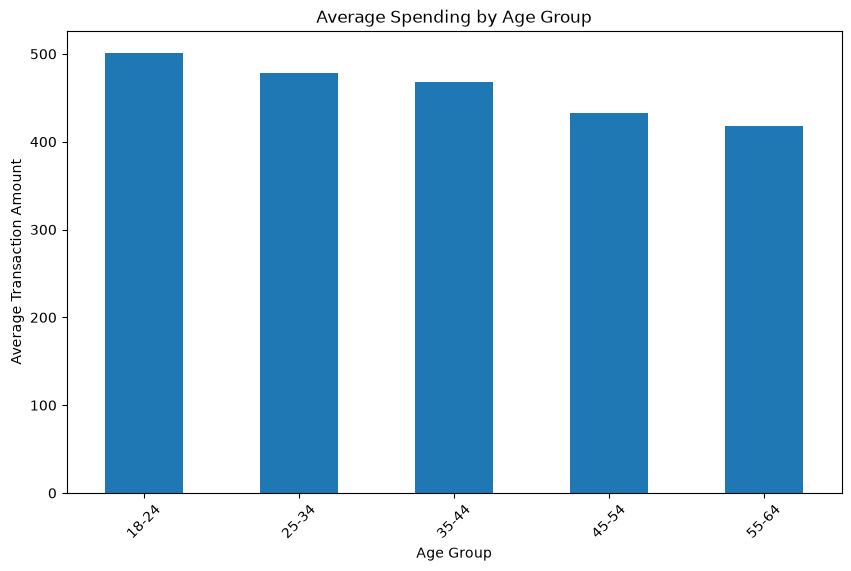

In [47]:
plt.figure(figsize=(10, 6))

age_group_spending.plot(kind="bar")

plt.title("Average Spending by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Transaction Amount")
plt.xticks(rotation=45)

plt.show()

### Observation — Average Spending by Age Group

The analysis compares the average transaction amount across different age
groups. Differences in average spending indicate that some customer age
groups may have higher spending levels than others. This insight can help
businesses develop targeted promotions and marketing strategies for
different customer segments.

# Conclusion and Business Recommendations

## Key Insights

1. The monthly and quarterly sales analysis shows how sales performance
   changes over time and helps identify periods of higher and lower sales.

2. The customer demographic analysis shows the distribution of customers
   across different age groups and genders.

3. Product category analysis shows differences in sales quantity and revenue
   contribution across product categories.

4. The correlation analysis highlights relationships between age, quantity,
   price per unit, and total transaction amount.

5. The age-group spending analysis shows that average transaction value
   differs across customer age groups.



# Actionable Business Recommendations

1. **Target high-value customer groups:** Businesses should identify age
   groups with higher average spending and create targeted offers,
   promotions, and loyalty campaigns for these customers.

2. **Focus on high-performing categories:** Product categories with higher
   sales volume or revenue should receive appropriate inventory levels and
   marketing support to maintain their performance.

3. **Use demographic-based marketing:** Customer age and gender information
   can be used to create more personalized marketing campaigns and product
   recommendations.

4. **Plan inventory based on sales trends:** Monthly and quarterly sales
   patterns can be used to improve inventory planning and reduce the risk of
   overstocking or stock shortages.

5. **Monitor sales relationships:** The relationships identified through
   correlation analysis can be monitored to better understand factors
   associated with transaction value and sales performance.

## Overall Conclusion

The exploratory data analysis provides useful insights into sales trends,
customer demographics, product category performance, and customer spending
behaviour. These findings can help businesses make data-driven decisions
related to marketing, inventory management, customer targeting, and sales
planning.